# 03 · Federated learning (XGBoost + MLP)

**Question:** can three hospitals that never share traffic reach the accuracy of a model trained on all data pooled?
**Reference points from notebook 02 (split_run test):** local-only site B 0.884 (6.6 false alarms/h) · best local 0.916 · centralised 0.927.

**What only leaves a client:** round 0 → class counts (for priors and class weights) and per-feature quantiles (MLP scaling); training rounds → trees or weight updates. Never windows, labels or IPs.

| Section | Experiment |
|---|---|
| 2 | Federated XGBoost building blocks: **FedXgbBagging** (each round every client adds trees to the shared model; same scheme as Flower's `FedXgbBagging`) and **FedXgbCyclic** (clients take turns) |
| 3 | **P1 · 3 hospital sites** — local-only vs federated vs centralised, scored on the global test and on each site's own test |
| 4 | **P3 · Dirichlet label skew** (5 clients, α = 0.1 / 0.5 / 5) — does federation help when clients see different attack mixes? |
| 5 | **Unseen hospital** — train on sites A + B, test on site C (`split_site`) |
| 6 | **MLP + FedAvg** (neural comparator) with federated quantile scaling |
| 7 | Communication cost and summary |

Implemented in plain Python (no Flower / Ray needed, works on Windows). The protocol is identical to a Flower deployment, so moving it onto real Flower clients later is a plumbing change, not a change to results.
Everything is logged to MLflow, experiment **vitalgate-federated**, with per-round learning curves.

**v2 (14 Nov) — fix after the first run.** Plain bagging *adds* every client's trees at full strength. Each client fits the same remaining error, so with n clients a round takes ≈ n× the intended step. With 3 sites this cost little (0.925 vs 0.928), but with 5 near-identical clients (Dirichlet α = 5) federated fell *below* local-only (0.869, best round 3, 12.8 false alarms/h). v2 adds **weighted bagging** (`agg="mean"`): each client's trees are scaled by its share of the training data, the tree-ensemble equivalent of FedAvg. Both versions are reported; P3 and the unseen-site test now use 3 seeds.

Set `RUN` below to skip sections you don't need to re-run.

Runtime on a laptop CPU: ≈ 45–75 min for everything. `FAST = True` → ≈ 15 min.

In [25]:
# 0 · Setup
import os, sys, json, time, copy, warnings
from pathlib import Path
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm
from scipy.spatial.distance import jensenshannon
from sklearn.preprocessing import LabelEncoder
from sklearn.metrics import f1_score, matthews_corrcoef, average_precision_score, roc_curve
from sklearn.neural_network import MLPClassifier
import xgboost as xgb
try:
    from IPython.display import display
except ImportError:
    display = print
warnings.filterwarnings("ignore")

FAST = False
MAIN_SEEDS = [0] if FAST else [0, 1, 2]      # seeds for the main P1 comparison
SEED = 0                                       # single seed for the MLP
RUN = dict(P1=True, P3=True, unseen=True, mlp=True)   # set False to skip a section
REPO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
PROC, MODELS = REPO / "data" / "processed", REPO / "models"
REP = REPO / "reports" / "federated"; REP.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(REPO / "src"))
import tracking, mlflow
EXP = "vitalgate-federated"; tracking.use_experiment(EXP)
plt.rcParams["figure.dpi"] = 110
print("xgboost", xgb.__version__, "| mlflow", mlflow.__version__, "| session", tracking.SESSION)

xgboost 3.4.1 | mlflow 3.18.0 | session 20261114-124645


## 1 · Data, features, metrics (same as notebook 02)

In [26]:
CFG = json.loads((MODELS / "xgb_config.json").read_text(encoding="utf-8"))
FEATURES, BEST, TAU = CFG["features"], CFG["best_params"], CFG.get("tau")
ROLL_BASE = CFG["rolling"]["base"]; ROLL_FEATS = [f"{b}_roll3" for b in ROLL_BASE]
RULE_CLASS = CFG["rule_class"]
win = pd.read_parquet(PROC / "windows_v2.parquet")

import features as FV
def add_rolling(frame, part_col):          # v3 history features (src/features.py)
    return FV.add_history(frame, part_col)

def prepare(part_col):
    f = add_rolling(win[win["label_class"] != RULE_CLASS].reset_index(drop=True), part_col)
    return f, le.transform(f["label_class"])

le = LabelEncoder().fit(win.loc[win["label_class"] != RULE_CLASS, "label_class"]); CLS = list(le.classes_); K = len(CLS)
BEN, REC = CLS.index("benign"), CLS.index("recon")
d, y = prepare("split_run")
TR, VA, TE = [(d["split_run"] == p).values for p in ("train", "val", "test")]
SITES = sorted(d["site"].unique())
X = d[FEATURES].to_numpy(np.float32)

def hours(frame, cap=60.0):
    t = frame.sort_values(["client_ip", "window_start"])
    return t.groupby("client_ip")["window_start"].diff().fillna(2.0).clip(upper=cap).sum() / 3600.0

def decide(prob, tau=None):
    if tau is None: return prob.argmax(1)
    p = prob.copy(); p[:, BEN] = -1
    return np.where(prob[:, BEN] >= tau, BEN, p.argmax(1))

def metrics(yt, prob, h):
    pred = decide(prob, TAU); yb, score = (yt != BEN).astype(int), 1 - prob[:, BEN]
    keep = yt != REC; pc = f1_score(yt, pred, labels=range(K), average=None, zero_division=0)
    return dict(macro_F1=f1_score(yt, pred, labels=range(K), average="macro", zero_division=0),
                macro_F1_no_recon=f1_score(yt[keep], pred[keep], labels=[i for i in range(K) if i != REC], average="macro", zero_division=0),
                MCC=matthews_corrcoef(yt, pred), PR_AUC=average_precision_score(yb, score),
                FP_per_wallclock_h=((pred != BEN) & (yt == BEN)).sum() / h,
                F1_exfiltration=pc[CLS.index("exfiltration")], F1_ransomware_like=pc[CLS.index("ransomware_like")])

H = {"val": hours(d[VA]), "test": hours(d[TE]), **{f"test_{s}": hours(d[TE & (d["site"] == s).values]) for s in SITES}}
SHOW = ["macro_F1", "macro_F1_no_recon", "F1_exfiltration", "F1_ransomware_like", "FP_per_wallclock_h"]
print(len(FEATURES), "features | params from notebook 02:", BEST, "| tau:", TAU)

83 features | params from notebook 02: {'depth': 8, 'lr': 0.1, 'weights': 'sqrt'} | tau: None


## 2 · Building blocks
**Round 0** — each client sends only its class counts → the server builds the global class prior (starting score) and the √-balanced class weights used by every client.
**FedXgbBagging** — every round each client grows `LOCAL_TREES` trees on its own data, starting from the current global model; the server appends all of them to the global model.
**FedXgbCyclic** — one client per round, in turn, grows trees on top of the global model.
The round with the best macro-F1 on validation is kept (federated evaluation = summing each client's confusion counts, which equals the pooled score).

In [27]:
LOCAL_TREES = 10
MAX_ROUNDS  = 40 if FAST else 80
PATIENCE    = 6

def xgb_params(seed):
    return dict(objective="multi:softprob", num_class=K, max_depth=int(BEST["depth"]), eta=float(BEST["lr"]),
                subsample=0.8, colsample_bytree=0.8, tree_method="hist", seed=int(seed), nthread=os.cpu_count() or 4,
                eval_metric="mlogloss")

def dmat(Xa, ya=None, w=None, margin=None):
    if margin is None: return xgb.DMatrix(Xa, label=ya, weight=w)
    try:    return xgb.DMatrix(Xa, label=ya, weight=w, base_margin=margin)
    except Exception: return xgb.DMatrix(Xa, label=ya, weight=w, base_margin=margin.ravel())

def class_weights(counts):
    return (counts.max() / np.maximum(counts, 1)) ** 0.5 if BEST.get("weights") == "sqrt" else np.ones(K)

def contrib(booster, Xa):
    return booster.predict(dmat(Xa, margin=np.zeros((len(Xa), K), np.float32)), output_margin=True).reshape(len(Xa), K)

def softmax(m):
    e = np.exp(m - m.max(1, keepdims=True)); return e / e.sum(1, keepdims=True)

def fed_xgb(clients, evals, mode="bagging", seed=0, agg="sum", log_every=1):
    # agg="sum": add every client's trees at full strength (Flower FedXgbBagging)
    # agg="mean": scale client i's trees by n_i / n (weighted bagging, FedAvg-style); cyclic always uses full strength
    # clients: list of (X, y); evals: dict name -> (X, y, hours); "val" must exist
    counts = sum(np.bincount(yc, minlength=K) for _, yc in clients)            # round 0
    prior = np.log(np.maximum(counts, 1) / counts.sum()).astype(np.float32); w_cls = class_weights(counts)
    m_tr = [np.tile(prior, (len(yc), 1)) for _, yc in clients]
    m_ev = {k: np.tile(prior, (len(v[1]), 1)) for k, v in evals.items()}
    sizes = np.array([len(yc) for _, yc in clients], float); share = sizes / sizes.sum()
    best, hist, since, sent = dict(f1=-1, round=0, m=None), [], 0, 0
    for t in range(1, MAX_ROUNDS + 1):
        who = [(t - 1) % len(clients)] if mode == "cyclic" else range(len(clients))
        upd, mb = [], 0.0
        for i in who:
            Xc, yc = clients[i]
            b = xgb.train(xgb_params(seed * 1000 + t * 10 + i), dmat(Xc, yc, w_cls[yc], m_tr[i]), LOCAL_TREES)
            mb += len(b.save_raw(raw_format="json")) / 1e6
            upd.append((b, 1.0 if (mode == "cyclic" or agg == "sum") else (1 / len(clients) if agg == "equal" else share[i])))
        for b, sc in upd:
            for i, (Xc, _) in enumerate(clients): m_tr[i] += sc * contrib(b, Xc)
            for k, (Xe, _, _) in evals.items(): m_ev[k] += sc * contrib(b, Xe)
        sent += mb
        r = metrics(evals["val"][1], softmax(m_ev["val"]), evals["val"][2])
        hist.append(dict(round=t, trees=t * LOCAL_TREES * len(upd), MB_up_this_round=mb, MB_up_total=sent, **r))
        if mlflow.active_run() and t % log_every == 0:
            tracking.log_metrics({"val_macro_F1": r["macro_F1"], "val_FP_per_h": r["FP_per_wallclock_h"], "MB_up_total": sent}, step=t)
        if r["macro_F1"] > best["f1"] + 1e-4:
            best = dict(f1=r["macro_F1"], round=t, m={k: v.copy() for k, v in m_ev.items()}); since = 0
        else:
            since += 1
            if since >= PATIENCE: break
    out = {k: metrics(v[1], softmax(best["m"][k]), v[2]) for k, v in evals.items()}
    return dict(best_round=best["round"], rounds_run=t, MB_up=sent, MB_per_round=sent / t, hist=pd.DataFrame(hist), scores=out)

def central_xgb(Xa, ya, Xv, yv, seed=0, fixed_rounds=None):
    # same model as notebook 02 (early stopping on val); used for local-only and centralised
    counts = np.bincount(ya, minlength=K); w = class_weights(counts)[ya]
    if fixed_rounds:
        return xgb.train(xgb_params(seed), dmat(Xa, ya, w), fixed_rounds)
    return xgb.train(xgb_params(seed), dmat(Xa, ya, w), 2000, evals=[(dmat(Xv, yv), "val")],
                     early_stopping_rounds=50, verbose_eval=False)

def predict(b, Xa):
    it = getattr(b, "best_iteration", None)
    p = b.predict(dmat(Xa), iteration_range=(0, it + 1)) if it is not None else b.predict(dmat(Xa))
    return p.reshape(len(Xa), K)

## 3 · P1: three hospital sites (local-only vs federated vs centralised)

In [28]:
site_mask = {s: (d["site"] == s).values for s in SITES}
clients_P1 = [(X[TR & site_mask[s]], y[TR & site_mask[s]]) for s in SITES]
evals_P1 = {"val": (X[VA], y[VA], H["val"]), "test": (X[TE], y[TE], H["test"]),
            **{f"test_{s}": (X[TE & site_mask[s]], y[TE & site_mask[s]], H[f"test_{s}"]) for s in SITES}}

def score_model(b):
    return {k: metrics(v[1], predict(b, v[0]), v[2]) for k, v in evals_P1.items()}

FED_VARIANTS = [("bagging", "sum", "federated (bagging, sum)"), ("bagging", "mean", "federated (bagging, weighted)"),
                ("cyclic", "sum", "federated (cyclic)")]
P1_rows, curves = [], {}
for seed in (MAIN_SEEDS if RUN["P1"] else []):
    for s in SITES:      # local-only: each site trains and early-stops on its own data
        with tracking.run(f"P1 local-only {s} · seed {seed}", params={"partition": "P1_sites", "setting": "local", "site": s, "seed": seed, **BEST},
                          tags={"stage": "P1", "setting": "local"}):
            b = central_xgb(X[TR & site_mask[s]], y[TR & site_mask[s]], X[VA & site_mask[s]], y[VA & site_mask[s]], seed)
            sc = score_model(b); tracking.log_metrics(sc["test"], prefix="test_")
        P1_rows.append(dict(setting=f"local-only {s}", seed=seed, **{f"{k}|{m}": v for k, r in sc.items() for m, v in r.items()}))
    with tracking.run(f"P1 centralised · seed {seed}", params={"partition": "P1_sites", "setting": "centralised", "seed": seed, **BEST},
                      tags={"stage": "P1", "setting": "centralised"}):
        b = central_xgb(X[TR], y[TR], X[VA], y[VA], seed); sc = score_model(b); tracking.log_metrics(sc["test"], prefix="test_")
    P1_rows.append(dict(setting="centralised", seed=seed, **{f"{k}|{m}": v for k, r in sc.items() for m, v in r.items()}))
    for mode, agg, label in FED_VARIANTS:
        with tracking.run(f"P1 {label} · seed {seed}", params={"partition": "P1_sites", "setting": f"fed_{mode}_{agg}", "seed": seed, "agg": agg,
                                                                "local_trees": LOCAL_TREES, "max_rounds": MAX_ROUNDS, **BEST},
                          tags={"stage": "P1", "setting": f"fed_{mode}_{agg}", "version": "v2"}):
            res = fed_xgb(clients_P1, evals_P1, mode, seed, agg)
            tracking.log_metrics(res["scores"]["test"], prefix="test_")
            tracking.log_metrics({"best_round": res["best_round"], "MB_up_total": res["MB_up"], "MB_per_round": res["MB_per_round"]})
        curves[(label, seed)] = res["hist"]
        P1_rows.append(dict(setting=label, seed=seed, best_round=res["best_round"], rounds_run=res["rounds_run"],
                            MB_up_total=res["MB_up"], MB_per_round=res["MB_per_round"],
                            **{f"{k}|{m}": v for k, r in res["scores"].items() for m, v in r.items()}))
    print(f"seed {seed} done")

P1 = pd.DataFrame(P1_rows)
if not RUN["P1"]: raise SystemExit("P1 skipped: later sections need it for the summary; set RUN['P1']=True")
def table(df, part="test", cols=SHOW):
    keep = [f"{part}|{c}" for c in cols]
    g = df.groupby("setting", sort=False)[keep]
    out = g.mean().round(3).astype(str) + " ± " + g.std().fillna(0).round(3).astype(str)
    out.columns = cols; return out
print("Global split_run test:"); P1_TABLE = table(P1); display(P1_TABLE)
print("macro-F1 on each site's own test windows:")
display(pd.DataFrame({s: P1.groupby("setting", sort=False)[f"test_{s}|macro_F1"].mean().round(3) for s in SITES}))

seed 0 done
seed 1 done
seed 2 done
Global split_run test:


,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
setting,,,,,
local-only A,0.948 ± 0.001,0.94 ± 0.001,0.823 ± 0.006,0.865 ± 0.0,0.363 ± 0.074
local-only B,0.929 ± 0.001,0.923 ± 0.001,0.753 ± 0.007,0.85 ± 0.006,1.6 ± 0.085
local-only C,0.944 ± 0.001,0.935 ± 0.001,0.809 ± 0.007,0.866 ± 0.0,0.511 ± 0.043
centralised,0.954 ± 0.001,0.947 ± 0.001,0.836 ± 0.003,0.878 ± 0.005,0.4 ± 0.058
"federated (bagging, sum)",0.951 ± 0.002,0.943 ± 0.002,0.823 ± 0.008,0.871 ± 0.005,0.632 ± 0.126
"federated (bagging, weighted)",0.952 ± 0.001,0.944 ± 0.001,0.834 ± 0.003,0.879 ± 0.003,0.4 ± 0.043
federated (cyclic),0.952 ± 0.002,0.944 ± 0.002,0.833 ± 0.006,0.879 ± 0.008,0.567 ± 0.081


macro-F1 on each site's own test windows:


,A,B,C
setting,,,
local-only A,0.960,0.919,0.968
local-only B,0.929,0.916,0.938
local-only C,0.951,0.915,0.967
centralised,0.964,0.926,0.975
"federated (bagging, sum)",0.962,0.924,0.968
"federated (bagging, weighted)",0.962,0.922,0.973
federated (cyclic),0.963,0.924,0.970


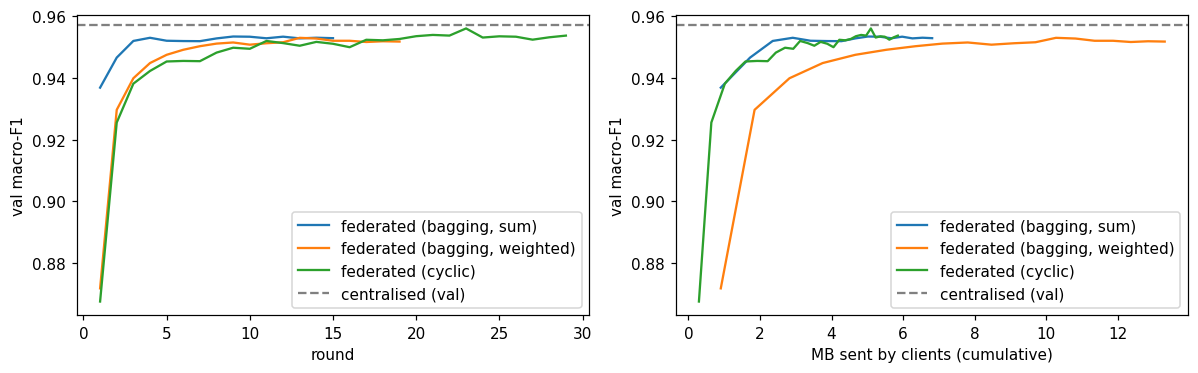

In [29]:
fig, ax = plt.subplots(1, 2, figsize=(11, 3.5))
for (label, seed), h in curves.items():
    if seed != MAIN_SEEDS[0]: continue
    ax[0].plot(h["round"], h["macro_F1"], label=label); ax[1].plot(h["MB_up_total"], h["macro_F1"], label=label)
cent = P1[P1.setting == "centralised"]["val|macro_F1"].mean() if "val|macro_F1" in P1 else None
for a in ax:
    if cent: a.axhline(cent, ls="--", c="grey", label="centralised (val)")
    a.set_ylabel("val macro-F1"); a.legend()
ax[0].set_xlabel("round"); ax[1].set_xlabel("MB sent by clients (cumulative)")
plt.tight_layout(); plt.savefig(REP / "P1_learning_curves.png"); plt.show()

## 4 · P3: Dirichlet label skew (5 clients)
Training windows are split across 5 clients with class proportions drawn from Dirichlet(α). Small α = each client sees mostly a few attack types — the case where federation should matter most.

In [30]:
def dirichlet_split(yy, n_clients, alpha, seed):
    rng = np.random.default_rng(seed); parts = [[] for _ in range(n_clients)]
    for c in range(K):
        idx = rng.permutation(np.where(yy == c)[0])
        cuts = (np.cumsum(rng.dirichlet([alpha] * n_clients)) * len(idx)).astype(int)[:-1]
        for i, p in enumerate(np.split(idx, cuts)): parts[i].extend(p.tolist())
    return [np.array(sorted(p), dtype=int) for p in parts]

tr_idx = np.where(TR)[0]; ytr = y[TR]
g = np.bincount(ytr, minlength=K) / len(ytr)
evals_g = {"val": (X[VA], y[VA], H["val"]), "test": (X[TE], y[TE], H["test"])}
b_cent = central_xgb(X[TR], y[TR], X[VA], y[VA], SEED); cent_test = metrics(y[TE], predict(b_cent, X[TE]), H["test"])
CENT_ROUNDS = int(b_cent.best_iteration) + 1

P3_rows = []
for seed in (MAIN_SEEDS if RUN["P3"] else []):          # seed changes both the client split and the training
    for alpha in [0.1, 0.5, 5.0]:
        parts = [tr_idx[p] for p in dirichlet_split(ytr, 5, alpha, seed)]
        parts = [p for p in parts if len(p) > 50]
        js = np.mean([jensenshannon(np.bincount(y[p], minlength=K) / len(p), g) for p in parts])
        missing = np.mean([(np.bincount(y[p], minlength=K) == 0).sum() for p in parts])
        loc = [metrics(y[TE], predict(central_xgb(X[p], y[p], None, None, seed, CENT_ROUNDS), X[TE]), H["test"]) for p in parts]
        common = dict(alpha=alpha, seed=seed, JS=js, missing_classes=missing)
        P3_rows += [dict(**common, setting="local-only (mean of clients)", **pd.DataFrame(loc).mean().to_dict()),
                    dict(**common, setting="local-only (best client)", **max(loc, key=lambda r: r["macro_F1"])),
                    dict(**common, setting="centralised", **cent_test)]
        for agg in ["sum", "mean"]:
            label = "federated (bagging, sum)" if agg == "sum" else "federated (bagging, weighted)"
            with tracking.run(f"P3 alpha={alpha} {label} · seed {seed}", params={"partition": "P3_dirichlet", "alpha": alpha, "agg": agg,
                                                                               "n_clients": len(parts), "seed": seed, "local_trees": LOCAL_TREES, **BEST},
                              tags={"stage": "P3", "setting": f"fed_bagging_{agg}", "version": "v2"}):
                res = fed_xgb([(X[p], y[p]) for p in parts], evals_g, "bagging", seed, agg)
                tracking.log_metrics(res["scores"]["test"], prefix="test_")
                tracking.log_metrics({"JS_divergence": js, "classes_missing_per_client": missing, "best_round": res["best_round"],
                                      "local_mean_macro_F1": np.mean([l["macro_F1"] for l in loc]),
                                      "local_best_macro_F1": max(l["macro_F1"] for l in loc)})
            P3_rows.append(dict(**common, setting=label, best_round=res["best_round"], **res["scores"]["test"]))
        print(f"seed {seed} alpha={alpha}: JS={js:.3f}, avg classes missing per client={missing:.1f}")
P3 = pd.DataFrame(P3_rows)
if len(P3):
    order = ["local-only (mean of clients)", "local-only (best client)", "federated (bagging, sum)", "federated (bagging, weighted)", "centralised"]
    p3m = P3.groupby(["setting", "alpha"])["macro_F1"].agg(["mean", "std"])
    P3_TABLE = (p3m["mean"].round(3).astype(str) + " ± " + p3m["std"].fillna(0).round(3).astype(str)).unstack("alpha").reindex(order)
    print("macro-F1 (mean ± std over seeds):"); display(P3_TABLE)
    print("false alarms per wall-clock client-hour (mean):")
    display(P3.groupby(["setting", "alpha"])["FP_per_wallclock_h"].mean().unstack("alpha").reindex(order).round(2))
    print("best round (federated):"); display(P3[P3.setting.str.startswith("federated")].groupby(["setting", "alpha"])["best_round"].mean().unstack("alpha").round(1))

seed 0 alpha=0.1: JS=0.500, avg classes missing per client=2.4
seed 0 alpha=0.5: JS=0.210, avg classes missing per client=0.0
seed 0 alpha=5.0: JS=0.081, avg classes missing per client=0.0
seed 1 alpha=0.1: JS=0.368, avg classes missing per client=2.6
seed 1 alpha=0.5: JS=0.186, avg classes missing per client=0.0
seed 1 alpha=5.0: JS=0.076, avg classes missing per client=0.0
seed 2 alpha=0.1: JS=0.601, avg classes missing per client=1.8
seed 2 alpha=0.5: JS=0.367, avg classes missing per client=0.2
seed 2 alpha=5.0: JS=0.071, avg classes missing per client=0.0
macro-F1 (mean ± std over seeds):


alpha,0.1,0.5,5.0
setting,,,
local-only (mean of clients),0.411 ± 0.031,0.834 ± 0.046,0.933 ± 0.001
local-only (best client),0.6 ± 0.045,0.891 ± 0.067,0.941 ± 0.002
"federated (bagging, sum)",0.864 ± 0.04,0.906 ± 0.027,0.921 ± 0.002
"federated (bagging, weighted)",0.707 ± 0.084,0.929 ± 0.016,0.949 ± 0.003
centralised,0.954 ± 0.0,0.954 ± 0.0,0.954 ± 0.0


false alarms per wall-clock client-hour (mean):


alpha,0.1,0.5,5.0
setting,,,
local-only (mean of clients),50.52,3.71,0.57
local-only (best client),3.07,3.95,0.65
"federated (bagging, sum)",0.99,4.88,5.62
"federated (bagging, weighted)",0.28,0.31,0.53
centralised,0.42,0.42,0.42


best round (federated):


alpha,0.1,0.5,5.0
setting,,,
"federated (bagging, sum)",4.3,1.3,1.0
"federated (bagging, weighted)",25.0,13.0,16.7


In [31]:
EQ_rows = []
for seed in MAIN_SEEDS:
    for alpha in [0.1, 0.5, 5.0]:
        parts = [tr_idx[p] for p in dirichlet_split(ytr, 5, alpha, seed)]
        parts = [p for p in parts if len(p) > 50]
        with tracking.run(f"P3 alpha={alpha} federated (bagging, equal) · seed {seed}",
                          params={"partition": "P3_dirichlet", "alpha": alpha, "agg": "equal", "seed": seed, **BEST},
                          tags={"stage": "P3", "setting": "fed_bagging_equal", "version": "v3"}):
            res = fed_xgb([(X[p], y[p]) for p in parts], evals_g, "bagging", seed, "equal")
            tracking.log_metrics(res["scores"]["test"], prefix="test_")
        EQ_rows.append(dict(alpha=alpha, seed=seed, best_round=res["best_round"], **res["scores"]["test"]))
EQ = pd.DataFrame(EQ_rows)
display(EQ.groupby("alpha")[["macro_F1", "FP_per_wallclock_h", "F1_exfiltration", "F1_ransomware_like", "best_round"]].agg(["mean", "std"]).round(3))
EQ.to_csv(REP / "P3_dirichlet_equal.csv", index=False, encoding="utf-8-sig")

macro_F1        FP_per_wallclock_h        F1_exfiltration         \
          mean    std               mean    std            mean    std   
alpha                                                                    
0.1      0.869  0.055              2.827  2.746           0.792  0.006   
0.5      0.945  0.002              0.623  0.354           0.811  0.017   
5.0      0.950  0.003              0.586  0.028           0.830  0.013   

      F1_ransomware_like        best_round          
                    mean    std       mean     std  
alpha                                               
0.1                0.828  0.018     18.000  11.136  
0.5                0.872  0.007     10.333   2.082  
5.0                0.880  0.008     16.000   7.000

## 5 · Unseen hospital: train on sites A + B, test on site C (`split_site`)

In [32]:
ds, ys = prepare("split_site")
Xs = ds[FEATURES].to_numpy(np.float32)
S_TR, S_VA, S_TE = [(ds["split_site"] == p).values for p in ("train", "val", "test")]
train_sites = sorted(ds.loc[S_TR, "site"].unique()); test_site = sorted(ds.loc[S_TE, "site"].unique())
print("train sites:", train_sites, "| test site:", test_site)
Hs = {"val": hours(ds[S_VA]), "test": hours(ds[S_TE])}
ev_s = {"val": (Xs[S_VA], ys[S_VA], Hs["val"]), "test": (Xs[S_TE], ys[S_TE], Hs["test"])}
U_rows = []
AB = "+".join(train_sites)
for seed in (MAIN_SEEDS if RUN["unseen"] else []):
    for s in train_sites:
        sm = (ds["site"] == s).values
        b = central_xgb(Xs[S_TR & sm], ys[S_TR & sm], Xs[S_VA & sm], ys[S_VA & sm], seed)
        U_rows.append(dict(setting=f"local-only {s}", seed=seed, **metrics(ys[S_TE], predict(b, Xs[S_TE]), Hs["test"])))
    b = central_xgb(Xs[S_TR], ys[S_TR], Xs[S_VA], ys[S_VA], seed)
    U_rows.append(dict(setting=f"centralised {AB}", seed=seed, **metrics(ys[S_TE], predict(b, Xs[S_TE]), Hs["test"])))
    for agg in ["sum", "mean"]:
        label = f"federated (bagging, {'sum' if agg == 'sum' else 'weighted'}) {AB}"
        with tracking.run(f"Unseen site {label} · seed {seed}", params={"partition": "split_site", "train_sites": train_sites, "test_site": test_site,
                                                                         "agg": agg, "seed": seed, **BEST},
                          tags={"stage": "unseen_site", "setting": f"fed_bagging_{agg}", "version": "v2"}):
            res = fed_xgb([(Xs[S_TR & (ds["site"] == s).values], ys[S_TR & (ds["site"] == s).values]) for s in train_sites], ev_s, "bagging", seed, agg)
            tracking.log_metrics(res["scores"]["test"], prefix="test_")
        U_rows.append(dict(setting=label, seed=seed, best_round=res["best_round"], **res["scores"]["test"]))
U = pd.DataFrame(U_rows)
if len(U):
    gU = U.groupby("setting", sort=False)[SHOW]
    UNSEEN = gU.mean().round(3).astype(str) + " ± " + gU.std().fillna(0).round(3).astype(str); display(UNSEEN)

train sites: ['A', 'B'] | test site: ['C']


,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h
setting,,,,,
local-only A,0.944 ± 0.002,0.935 ± 0.003,0.811 ± 0.013,0.88 ± 0.005,0.887 ± 0.12
local-only B,0.905 ± 0.001,0.89 ± 0.001,0.619 ± 0.001,0.824 ± 0.008,5.02 ± 0.118
centralised A+B,0.953 ± 0.001,0.946 ± 0.001,0.838 ± 0.001,0.897 ± 0.006,0.868 ± 0.029
"federated (bagging, sum) A+B",0.948 ± 0.002,0.939 ± 0.002,0.82 ± 0.006,0.882 ± 0.006,0.985 ± 0.056
"federated (bagging, weighted) A+B",0.949 ± 0.002,0.94 ± 0.002,0.821 ± 0.009,0.887 ± 0.003,0.99 ± 0.167


## 6 · MLP + FedAvg (neural comparator)
Scaling uses a **federated quantile transform**: each client sends 201 quantiles per feature (not data); the server averages them. Then 3-layer MLP (128-64), one local epoch per round, FedAvg weighted by client size.

In [33]:
NN_FEATURES = [f for f in FEATURES if not f.startswith("n_calling_ae")]
Xn = FV.fill_for_nn(d[NN_FEATURES]).to_numpy(np.float64)
QS = np.linspace(0, 1, 201)
local_q = [np.quantile(Xn[TR & site_mask[s]], QS, axis=0) for s in SITES]
n_site = np.array([(TR & site_mask[s]).sum() for s in SITES])
GQ = sum(n * q for n, q in zip(n_site, local_q)) / n_site.sum()
GQ = GQ + np.arange(len(QS))[:, None] * 1e-9                       # strictly increasing for interp
def qtf(A):
    U = np.column_stack([np.interp(A[:, j], GQ[:, j], QS) for j in range(A.shape[1])])
    return norm.ppf(np.clip(U, 1e-3, 1 - 1e-3))
Z = qtf(Xn)

MLP_ROUNDS = 25 if FAST else 50
def new_mlp(seed):
    m = MLPClassifier((128, 64), learning_rate_init=1e-3, batch_size=256, random_state=seed)
    first = np.concatenate([np.where(y[TR] == c)[0][:2] for c in range(K)])
    m.partial_fit(Z[TR][first], y[TR][first], classes=np.arange(K)); return m

def get_w(m): return [w.copy() for w in m.coefs_] + [b.copy() for b in m.intercepts_]
def set_w(m, ws):
    n = len(m.coefs_); m.coefs_ = [w.copy() for w in ws[:n]]; m.intercepts_ = [b.copy() for b in ws[n:]]

def fedavg_mlp(client_masks, seed, name, setting):
    rng = np.random.default_rng(seed)
    glob = new_mlp(seed); locs = [new_mlp(seed + 1 + i) for i in range(len(client_masks))]
    share = np.array([m.sum() for m in client_masks], float); share /= share.sum()
    best, since = (-1, 0, None), 0
    with tracking.run(name, params={"model": "MLP 128-64", "setting": setting, "rounds": MLP_ROUNDS, "seed": seed}, tags={"stage": "mlp", "setting": setting}):
        for t in range(1, MLP_ROUNDS + 1):
            ws = []
            for m, cm in zip(locs, client_masks):
                set_w(m, get_w(glob)); idx = rng.permutation(np.where(cm)[0])
                m.partial_fit(Z[idx], y[idx]); ws.append(get_w(m))
            set_w(glob, [sum(s * w[l] for s, w in zip(share, ws)) for l in range(len(ws[0]))])
            r = metrics(y[VA], glob.predict_proba(Z[VA]), H["val"]); tracking.log_metrics({"val_macro_F1": r["macro_F1"]}, step=t)
            if r["macro_F1"] > best[0] + 1e-4: best, since = (r["macro_F1"], t, get_w(glob)), 0
            else:
                since += 1
                if since >= PATIENCE: break
        set_w(glob, best[2]); te = metrics(y[TE], glob.predict_proba(Z[TE]), H["test"])
        tracking.log_metrics(te, prefix="test_"); tracking.log_metrics({"best_round": best[1]})
    return dict(setting=setting, best_round=best[1], **te)

MLP_T = None
if RUN["mlp"]:
    MLP_rows = [fedavg_mlp([TR & site_mask[s]], SEED, f"MLP local-only {s}", f"local-only {s}") for s in SITES]
    MLP_rows.append(fedavg_mlp([TR], SEED, "MLP centralised", "centralised"))
    MLP_rows.append(fedavg_mlp([TR & site_mask[s] for s in SITES], SEED, "MLP FedAvg (3 sites)", "federated (FedAvg)"))
    MLP_T = pd.DataFrame(MLP_rows).set_index("setting"); display(MLP_T[SHOW + ["best_round"]].round(3))

,macro_F1,macro_F1_no_recon,F1_exfiltration,F1_ransomware_like,FP_per_wallclock_h,best_round
setting,,,,,,
local-only A,0.924,0.912,0.772,0.784,1.116,22
local-only B,0.911,0.898,0.742,0.746,1.200,24
local-only C,0.934,0.924,0.812,0.827,1.060,21
centralised,0.944,0.935,0.823,0.840,0.893,12
federated (FedAvg),0.943,0.933,0.806,0.844,0.697,26


## 7 · Summary, communication cost, save

In [34]:
parts = {"P1 XGBoost (split_run test)": P1_TABLE}
if RUN["unseen"]: parts["Unseen site C"] = UNSEEN
if MLP_T is not None: parts["MLP (split_run test)"] = MLP_T[SHOW].round(3).astype(str)
summary = pd.concat(parts); display(summary)
comm = P1[P1.setting.str.startswith("federated")].groupby("setting")[["best_round", "rounds_run", "MB_per_round", "MB_up_total"]].mean().round(3)
comm["MB_to_reach_best_round"] = (comm["MB_per_round"] * comm["best_round"]).round(2)
print("Communication (P1, mean over seeds):"); display(comm)

P1.to_csv(REP / "P1_sites_all_seeds.csv", index=False, encoding="utf-8-sig")
P1_TABLE.to_csv(REP / "P1_sites_summary.csv", encoding="utf-8-sig")
if RUN["P3"]: P3.to_csv(REP / "P3_dirichlet.csv", index=False, encoding="utf-8-sig"); P3_TABLE.to_csv(REP / "P3_dirichlet_summary.csv", encoding="utf-8-sig")
if RUN["unseen"]: U.to_csv(REP / "unseen_site_all_seeds.csv", index=False, encoding="utf-8-sig"); UNSEEN.to_csv(REP / "unseen_site.csv", encoding="utf-8-sig")
if MLP_T is not None: MLP_T.to_csv(REP / "mlp_fedavg.csv", encoding="utf-8-sig")
with tracking.run("Federated summary v2", tags={"stage": "summary", "version": "v2"}):
    for name in ["P1_sites_summary.csv", "P3_dirichlet_summary.csv", "unseen_site.csv", "mlp_fedavg.csv"]:
        tracking.log_files(REP / name)
    tracking.log_files(REP / "P1_learning_curves.png")
print("saved to", REP)

macro_F1  \
                            setting                                            
P1 XGBoost (split_run test) local-only A                       0.948 ± 0.001   
                            local-only B                       0.929 ± 0.001   
                            local-only C                       0.944 ± 0.001   
                            centralised                        0.954 ± 0.001   
                            federated (bagging, sum)           0.951 ± 0.002   
                            federated (bagging, weighted)      0.952 ± 0.001   
                            federated (cyclic)                 0.952 ± 0.002   
Unseen site C               local-only A                       0.944 ± 0.002   
                            local-only B                       0.905 ± 0.001   
                            centralised A+B                    0.953 ± 0.001   
                            federated (bagging, sum) A+B       0.948 ± 0.002   
                            federated (bagging, weighted) A+B  0.949 ± 0.002   
MLP (split_run test)        local-only A                               0.924   
                            local-only B                               0.911   
                            local-only C                               0.934   
                            centralised                                0.944   
                            federated (FedAvg)                         0.943   

                                                              macro_F1_no_recon  \
                            setting                                               
P1 XGBoost (split_run test) local-only A                           0.94 ± 0.001   
                            local-only B                          0.923 ± 0.001   
                            local-only C                          0.935 ± 0.001   
                            centralised                           0.947 ± 0.001   
                            federated (bagging, sum)              0.943 ± 0.002   
                            federated (bagging, weighted)         0.944 ± 0.001   
                            federated (cyclic)                    0.944 ± 0.002   
Unseen site C               local-only A                          0.935 ± 0.003   
                            local-only B                           0.89 ± 0.001   
                            centralised A+B                       0.946 ± 0.001   
                            federated (bagging, sum) A+B          0.939 ± 0.002   
                            federated (bagging, weighted) A+B      0.94 ± 0.002   
MLP (split_run test)        local-only A                                  0.912   
                            local-only B                                  0.898   
                            local-only C                                  0.924   
                            centralised                                   0.935   
                            federated (FedAvg)                            0.933   

                                                              F1_exfiltration  \
                            setting                                             
P1 XGBoost (split_run test) local-only A                        0.823 ± 0.006   
                            local-only B                        0.753 ± 0.007   
                            local-only C                        0.809 ± 0.007   
                            centralised                         0.836 ± 0.003   
                            federated (bagging, sum)            0.823 ± 0.008   
                            federated (bagging, weighted)       0.834 ± 0.003   
                            federated (cyclic)                  0.833 ± 0.006   
Unseen site C               local-only A                        0.811 ± 0.013   
                            local-only B                        0.619 ± 0.001   
                            centralised A+B                     0.838 ± 0.001 

Communication (P1, mean over seeds):


,best_round,rounds_run,MB_per_round,MB_up_total,MB_to_reach_best_round
setting,,,,,
"federated (bagging, sum)",5.667,11.667,0.507,5.810,2.87
"federated (bagging, weighted)",11.000,17.000,0.728,12.340,8.01
federated (cyclic),14.000,20.000,0.236,4.566,3.30


saved to c:\Users\rashi\Desktop\VitalGate Project Code\reports\federated


In [35]:
EQ2 = []
for seed in MAIN_SEEDS:
    with tracking.run(f"P1 federated (bagging, equal) · seed {seed}",
                      params={"partition": "P1_sites", "agg": "equal", "seed": seed, "local_trees": LOCAL_TREES, **BEST},
                      tags={"stage": "P1", "setting": "fed_bagging_equal", "version": "v3"}):
        res = fed_xgb(clients_P1, evals_P1, "bagging", seed, "equal")
        tracking.log_metrics(res["scores"]["test"], prefix="test_")
    EQ2.append(dict(test="3 sites (split_run test)", seed=seed, best_round=res["best_round"],
                    MB_to_best=res["MB_per_round"] * res["best_round"], **res["scores"]["test"],
                    **{f"own_{s}": res["scores"][f"test_{s}"]["macro_F1"] for s in SITES}))
    with tracking.run(f"Unseen site federated (bagging, equal) · seed {seed}",
                      params={"partition": "split_site", "agg": "equal", "seed": seed, **BEST},
                      tags={"stage": "unseen_site", "setting": "fed_bagging_equal", "version": "v3"}):
        res = fed_xgb([(Xs[S_TR & (ds["site"] == s).values], ys[S_TR & (ds["site"] == s).values]) for s in train_sites],
                      ev_s, "bagging", seed, "equal")
        tracking.log_metrics(res["scores"]["test"], prefix="test_")
    EQ2.append(dict(test="unseen site C", seed=seed, best_round=res["best_round"],
                    MB_to_best=res["MB_per_round"] * res["best_round"], **res["scores"]["test"]))
EQ2 = pd.DataFrame(EQ2)
cols = SHOW + ["best_round", "MB_to_best"] + [f"own_{s}" for s in SITES]
display(EQ2.groupby("test")[cols].agg(["mean", "std"]).round(3))
EQ2.to_csv(REP / "equal_scaling_P1_unseen.csv", index=False, encoding="utf-8-sig")

macro_F1        macro_F1_no_recon         \
                             mean    std              mean    std   
test                                                                
3 sites (split_run test)    0.953  0.001             0.945  0.001   
unseen site C               0.951  0.001             0.943  0.001   

                         F1_exfiltration        F1_ransomware_like         \
                                    mean    std               mean    std   
test                                                                        
3 sites (split_run test)           0.836  0.006              0.879  0.003   
unseen site C                      0.828  0.002              0.892  0.006   

                         FP_per_wallclock_h        best_round         \
                                       mean    std       mean    std   
test                                                                   
3 sites (split_run test)              0.391  0.028     12.333  0.577   
unseen site C                         0.929  0.064     13.333  1.528   

                         MB_to_best         own_A         own_B         own_C  \
                               mean    std   mean    std   mean    std   mean   
test                                                                            
3 sites (split_run test)       8.77  0.321  0.963  0.001  0.924  0.002  0.974   
unseen site C                  5.44  0.431    NaN    NaN    NaN    NaN    NaN   

                                 
                            std  
test                             
3 sites (split_run test)  0.002  
unseen site C               NaN